# Clasificación de imágenes: desde cero, MobileNetV2 y VGG16

Comparación de tres estrategias para clasificar gestos de piedra, papel o tijera:

1. Una CNN entrenada desde cero.
2. MobileNetV2 con transferencia de aprendizaje.
3. VGG16 con transferencia de aprendizaje.

El dataset se parte en entrenamiento, validación y test (70/15/15). La validación se usa para elegir
el mejor modelo y el test solo para medir el resultado final.

## Antes de ejecutar

En Colab, añade los secretos `userName` y `apiKey` de Kaggle en el panel de Secrets. El dataset se
descarga con `kagglehub` y no se versiona en el repositorio. Si la librería no está instalada,
ejecuta `!pip install -q kagglehub`.


# Desarrollo


## Funciones Utilitarias

### Descarga del Dataset

In [1]:
import os
import kagglehub
import shutil
from pathlib import Path

# En Colab, si kagglehub no está instalado: !pip install -q kagglehub
# Las credenciales se leen de los Secrets de Colab; en local, de ~/.kaggle/kaggle.json.
try:
    from google.colab import userdata  # type: ignore
    os.environ["KAGGLE_USERNAME"] = userdata.get("userName")
    os.environ["KAGGLE_KEY"] = userdata.get("apiKey")
except Exception:
    pass


def descargar_dataset(nombre_dataset: str, ruta_almacenar_dataset: str) -> Path:
  ruta_destino: Path = Path(ruta_almacenar_dataset)
  if ruta_destino.is_dir():
      print(f"El dataset ya se encuentra en: {ruta_destino}")
      return ruta_destino

  print(f"Descargando el dataset {nombre_dataset} desde Kaggle usando kagglehub...")
  ruta_origen = kagglehub.dataset_download(nombre_dataset)

  print(f"Moviendo archivos al directorio de trabajo local '{ruta_destino}' ...")
  shutil.copytree(ruta_origen, ruta_destino)

  return ruta_destino


def descargar_y_preparar_dataset_rockpaperscissors(ruta_almacenar_dataset: str) -> str:
  ruta_destino: Path = descargar_dataset("drgfreeman/rockpaperscissors", ruta_almacenar_dataset)

  # Limpiamos archivos basura que suelen venir en datasets de Kaggle
  if (ruta_destino / "rps-cv-images").exists():
      shutil.rmtree(ruta_destino / "rps-cv-images")
  if (ruta_destino / "README_rpc-cv-images.txt").exists():
      os.remove(ruta_destino / "README_rpc-cv-images.txt")

  print(f"¡Carga completada! Datos listos en: {ruta_destino}")
  return str(ruta_destino)


### Visualizar Dataset Original

In [2]:
CLASES = ['rock', 'paper', 'scissors']
def ver_dataset_original(ruta, clases):
  import matplotlib.pyplot as plt
  import matplotlib.image as mpimg
  import random

  plt.figure(figsize=(10, 4))
  for i, clase in enumerate(clases):
      ruta_clase = os.path.join(ruta, clase)
      num_imagenes = len(os.listdir(ruta_clase))

      imagen_ejemplo = os.path.join(ruta_clase, os.listdir(ruta_clase)[random.randint(0, num_imagenes - 1)])
      img = mpimg.imread(imagen_ejemplo)

      ax = plt.subplot(1, 3, i + 1)
      ax.imshow(img)
      ax.set_title(f"Clase: {clase} - {num_imagenes} Imagenes\nShape: {img.shape}")
      ax.axis("off")

  plt.tight_layout()
  plt.show()

### Obtener los Datos de Entrenamiento y Test desde el Dataset

In [3]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 123
LABEL_MODEL = "categorical"
PROPORCIONES = (0.70, 0.15, 0.15)


def crear_splits_estratificados(ruta_origen, ruta_destino, proporciones=PROPORCIONES, seed=SEED):
  """Copia el dataset en train/val/test manteniendo la proporción por clase."""
  import shutil
  from pathlib import Path
  from sklearn.model_selection import train_test_split

  ruta_origen = Path(ruta_origen)
  ruta_destino = Path(ruta_destino)
  shutil.rmtree(ruta_destino, ignore_errors=True)

  for clase in CLASES:
    archivos = sorted((ruta_origen / clase).glob("*"))
    train, resto = train_test_split(
        archivos, test_size=proporciones[1] + proporciones[2], random_state=seed
    )
    val, test = train_test_split(
        resto,
        test_size=proporciones[2] / (proporciones[1] + proporciones[2]),
        random_state=seed,
    )
    for particion, lista in (("train", train), ("val", val), ("test", test)):
      destino = ruta_destino / particion / clase
      destino.mkdir(parents=True, exist_ok=True)
      for archivo in lista:
        shutil.copy2(archivo, destino / archivo.name)
    print(f"{clase}: train={len(train)}, val={len(val)}, test={len(test)}")

  return ruta_destino


def obtener_datasets(ruta, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode=LABEL_MODEL):
  import tensorflow as tf
  return tuple(
      tf.keras.utils.image_dataset_from_directory(
          str(Path(ruta) / particion),
          class_names=CLASES,
          image_size=image_size,
          batch_size=batch_size,
          label_mode=label_mode,
          shuffle=(particion == "train"),
      )
      for particion in ("train", "val", "test")
  )


### Visualizar los Datos del Dataset (Usado para el dataset ya ajustado)

In [4]:
def ver_dataset(dataset):
  import matplotlib.pyplot as plt
  import tensorflow as tf

  class_names = dataset.class_names

  plt.figure(figsize=(10,10))

  for images, labels in dataset.take(1):
      for i in range(3):
          ax = plt.subplot(3,3,i+1)
          plt.imshow(images[i].numpy().astype("uint8"))
          plt.title(class_names[tf.argmax(labels[i]).numpy()])
          plt.axis("off")

  plt.show()

### Optimizar Rendimiento Dataset

In [5]:
def optimizar_rendimiento_dataset(train_dataset, val_dataset, test_dataset):
  import tensorflow as tf
  AUTOTUNE = tf.data.AUTOTUNE
  return (train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE),
          val_dataset.cache().prefetch(buffer_size=AUTOTUNE),
          test_dataset.cache().prefetch(buffer_size=AUTOTUNE))


### Callbacks para el Entrenamiento

In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

RUTA_MODELOS = "./modelos_guardados_rockpaperscissors"

def obtener_callbacks_entrenamiento(nombre_modelo_checkpoint: str,
                                    patience_early_stopping = 10,
                                    patience_reduce_lr = 5):
  if not os.path.exists(RUTA_MODELOS):
    os.makedirs(RUTA_MODELOS)

  early_stopping = EarlyStopping(
      monitor='val_loss',
      patience=patience_early_stopping,
      restore_best_weights=True,
      verbose=1
  )

  reduce_lr = ReduceLROnPlateau(
      monitor='val_loss',
      factor=0.5,
      patience=patience_reduce_lr,
      min_lr=1e-6,
      verbose=1
  )

  ruta_modelo = os.path.join(RUTA_MODELOS, nombre_modelo_checkpoint)
  model_checkpoint = ModelCheckpoint(
      filepath=ruta_modelo,
      monitor='val_loss',
      save_best_only=True,
      verbose=1
  )
  print(f"El mejor modelo se guardara en: {ruta_modelo}")
  return [early_stopping, reduce_lr, model_checkpoint]

### Graficas para Evaluacion del Modelo

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
from IPython.display import display, Markdown

def graficar_evaluacion_cuantitativa(modelo, test_dataset):
  loss, accuracy = modelo.evaluate(test_dataset, verbose=1)

  datos_evaluacion = {
      "Métrica": ["Pérdida (Loss)", "Precisión (Accuracy)"],
      "Valor obtenido": [f"{loss:.4f}", f"{accuracy*100:.2f}%"]
  }

  tabla_resultados = pd.DataFrame(datos_evaluacion)
  display(Markdown("### Evaluación Cuantitativa Global (Test)"))
  display(tabla_resultados)

def graficar_precision_y_perdida(history):
  acc = history.history['accuracy']
  val_acc = history.history['val_accuracy']
  loss_hist = history.history['loss']
  val_loss_hist = history.history['val_loss']
  epochs_range = range(1, len(acc) + 1)

  plt.figure(figsize=(14, 5))

  plt.subplot(1, 2, 1)
  plt.plot(epochs_range, acc, label='Precisión Entrenamiento', color='blue', linewidth=2)
  plt.plot(epochs_range, val_acc, label='Precisión Validación', color='orange', linewidth=2)
  plt.title('Evolución de la Precisión (Accuracy)')
  plt.xlabel('Épocas')
  plt.ylabel('Precisión')
  plt.legend(loc='lower right')
  plt.grid(True, linestyle='--', alpha=0.7)

  plt.subplot(1, 2, 2)
  plt.plot(epochs_range, loss_hist, label='Pérdida Entrenamiento', color='blue', linewidth=2)
  plt.plot(epochs_range, val_loss_hist, label='Pérdida Validación', color='orange', linewidth=2)
  plt.title('Evolución de la Pérdida (Loss)')
  plt.xlabel('Épocas')
  plt.ylabel('Pérdida')
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.7)

  plt.tight_layout()
  plt.show()

def obtener_y_true_y_pred(modelo, test_dataset):
  y_true = []
  y_pred_probs = []

  for images, labels in test_dataset:
      y_true.extend(np.argmax(labels.numpy(), axis=1))
      preds = modelo.predict(images, verbose=0)
      y_pred_probs.extend(preds)

  y_pred = np.argmax(y_pred_probs, axis=1)

  return (y_true, y_pred)

def graficar_analisis_errores_por_clase(y_true, y_pred, clases=CLASES):
  reporte_dict = classification_report(y_true, y_pred, target_names=clases, output_dict=True)
  tabla_errores = pd.DataFrame(reporte_dict).T
  tabla_errores = tabla_errores.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
  tabla_errores.columns = ['Precisión (Precision)', 'Exhaustividad (Recall)', 'F1-Score', 'Total de Imágenes (Support)']
  tabla_errores = tabla_errores.round(4)
  tabla_errores['Total de Imágenes (Support)'] = tabla_errores['Total de Imágenes (Support)'].astype(int)
  display(Markdown("### Análisis de Errores y Rendimiento por Clase"))
  display(tabla_errores)

def graficar_matriz_confusion(y_true, y_pred, clases=CLASES):
  cm = confusion_matrix(y_true, y_pred)
  plt.figure(figsize=(8, 6))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
  plt.title('Matriz de Confusión')
  plt.ylabel('Clase Real')
  plt.xlabel('Clase Predicha')
  plt.show()


def graficar_evaluacion_modelo(modelo, test_dataset, history):
  y_true, y_pred = obtener_y_true_y_pred(modelo, test_dataset)
  graficar_evaluacion_cuantitativa(modelo, test_dataset)
  print("\n\n")
  graficar_precision_y_perdida(history)
  print("\n\n")
  graficar_analisis_errores_por_clase(y_true, y_pred)
  print("\n\n")
  graficar_matriz_confusion(y_true, y_pred)

## Estrategia 1: Entrenar desde cero o from scratch

Se descargará usando el dataset descargado desde https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors

#### Carga del conjunto de datos

In [8]:
RUTA_DATASET = descargar_y_preparar_dataset_rockpaperscissors(ruta_almacenar_dataset="./rockpaperscissors")
RUTA_SPLITS = crear_splits_estratificados(RUTA_DATASET, "./rockpaperscissors_splits")


Descargando el dataset drgfreeman/rockpaperscissors desde Kaggle usando kagglehub...
Using Colab cache for faster access to the 'rockpaperscissors' dataset.
Moviendo archivos al directorio de trabajo local 'rockpaperscissors' ...
¡Carga completada! Datos listos en: rockpaperscissors
rock: train=508, val=109, test=109
paper: train=498, val=107, test=107
scissors: train=525, val=112, test=113


### Inspección del conjunto de datos

El dataset contiene en total 2188 imagenes correspondiente a:
- **Piedra:** 'Rock' (726 images)
- **Papel:** 'Paper' (710 images)
- **Tijera:** 'Scissors' (752 images).

Todas las imágenes son imágenes RGB de 300 píxeles de ancho por 200 píxeles de alto en formato .png

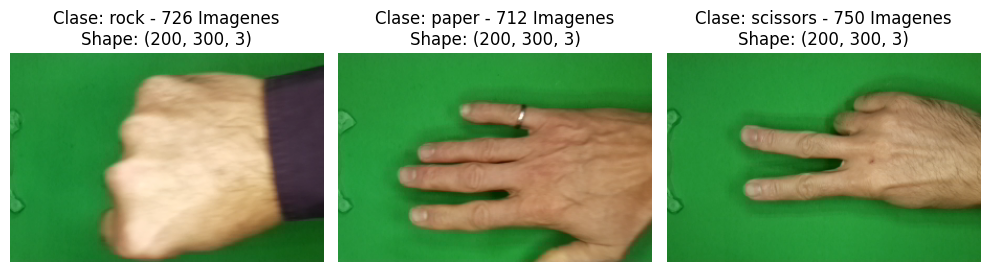

In [9]:
ver_dataset_original(ruta=RUTA_DATASET, clases=CLASES)

### Acondicionamiento del conjunto de datos

#### Partición de entrenamiento, validación y test

Found 1531 files belonging to 3 classes.
Found 328 files belonging to 3 classes.
Found 329 files belonging to 3 classes.


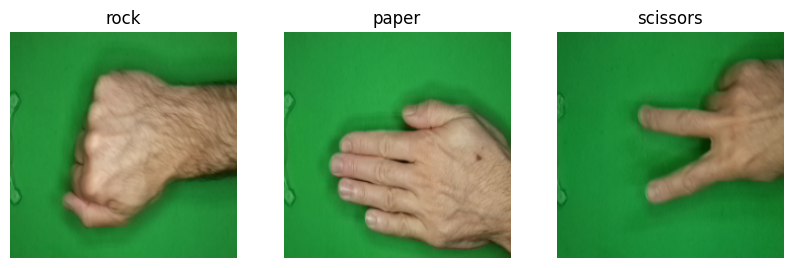

In [10]:
train_dataset, val_dataset, test_dataset = obtener_datasets(RUTA_SPLITS)
ver_dataset(train_dataset)
train_dataset, val_dataset, test_dataset = optimizar_rendimiento_dataset(train_dataset, val_dataset, test_dataset)


#### Data Generator

In [11]:
def agregar_capas_aumento_datos(model, input_shape) :
  from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom
  model.add(RandomFlip("horizontal", input_shape=input_shape, name="Aug_Flip"))
  model.add(RandomRotation(0.2, name="Aug_Rotation"))
  model.add(RandomZoom(0.2, name="Aug_Zoom"))
  return model

### Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución

In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2

def construir_modelo_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = Sequential(name="CNN_piedra_papel_tijera")
    model = agregar_capas_aumento_datos(model, input_shape)

    model.add(Conv2D(32, (3, 3), padding='same', activation='relu', name="Conv_1"))
    model.add(BatchNormalization(name="BN_1"))
    model.add(MaxPooling2D((2, 2), name="Pool_1"))

    model.add(Conv2D(64, (3, 3), padding='same', activation='relu', name="Conv_2"))
    model.add(BatchNormalization(name="BN_2"))
    model.add(MaxPooling2D((2, 2), name="Pool_2"))

    model.add(Conv2D(128, (3, 3), padding='same', activation='relu',
                     kernel_regularizer=l2(0.001), name="Conv_3_L2"))
    model.add(BatchNormalization(name="BN_3"))
    model.add(MaxPooling2D((2, 2), name="Pool_3"))

    model.add(GlobalAveragePooling2D(name="Global_Avg_Pool"))
    model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.001), name="Dense_1"))
    model.add(Dropout(0.5, name="Dropout_1"))
    model.add(Dense(num_classes, activation='softmax', name="Output_Layer"))

    return model

modelo_cnn = construir_modelo_cnn()
modelo_cnn.summary()
modelo_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "CNN_piedra_papel_tijera"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Aug_Flip (RandomFlip)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aug_Rotation (RandomRotation)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aug_Zoom (RandomZoom)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_1 (BatchNormalization)       │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_1 (MaxPooling2D)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_2 (BatchNormalization)       │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_2 (MaxPooling2D)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3_L2 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_3 (BatchNormalization)       │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_3 (MaxPooling2D)           │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Global_Avg_Pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,043 (433.76 KB)

 Trainable params: 110,595 (432.01 KB)

 Non-trainable params: 448 (1.75 KB)

### Monitorización del proceso de entrenamiento para la toma de decisiones

In [13]:
lista_callbacks = obtener_callbacks_entrenamiento(nombre_modelo_checkpoint="estrategia_1_from_scratch.keras")
EPOCHS = 100

history_estrategia_1 = modelo_cnn.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=lista_callbacks,
    verbose=1
)

print("\n¡Entrenamiento finalizado! El mejor modelo ha sido guardado.")

El mejor modelo se guardara en: ./modelos_guardados_rockpaperscissors/estrategia_1_from_scratch.keras
Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5435 - loss: 1.1453
Epoch 1: val_loss improved from None to 1.71549, saving model to ./modelos_guardados_rockpaperscissors/estrategia_1_from_scratch.keras

Epoch 1: finished saving model to ./modelos_guardados_rockpaperscissors/estrategia_1_from_scratch.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 161ms/step - accuracy: 0.6120 - loss: 1.0335 - val_accuracy: 0.3720 - val_loss: 1.7155 - learning_rate: 0.0010
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.7004 - loss: 0.8860
Epoch 2: val_loss did not improve from 1.71549
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.7440 - loss: 0.8004 - val_accuracy: 0.3323 - val_loss: 2.2200 - learning_rate: 0.0010
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.8413 - loss: 0.6229
Epoch 3: val_loss did not improve from 1.71549
48/48 ━━━━━━━━━━━━━━

### Evaluación del modelo predictivo y planteamiento de la siguiente prueba experimental

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9970 - loss: 0.0521


### Evaluación Cuantitativa Global (Test)

,Métrica,Valor obtenido
0,Pérdida (Loss),0.0521
1,Precisión (Accuracy),99.70%


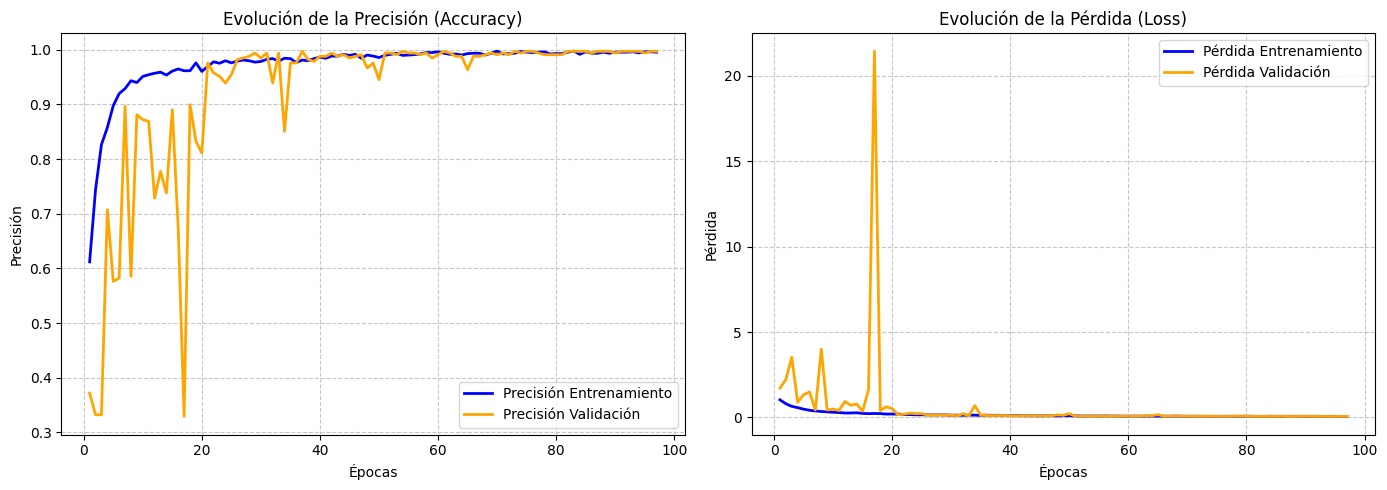

### Análisis de Errores y Rendimiento por Clase

,Precisión (Precision),Exhaustividad (Recall),F1-Score,Total de Imágenes (Support)
rock,1.0000,1.0000,1.0000,109
paper,1.0000,0.9907,0.9953,107
scissors,0.9912,1.0000,0.9956,113


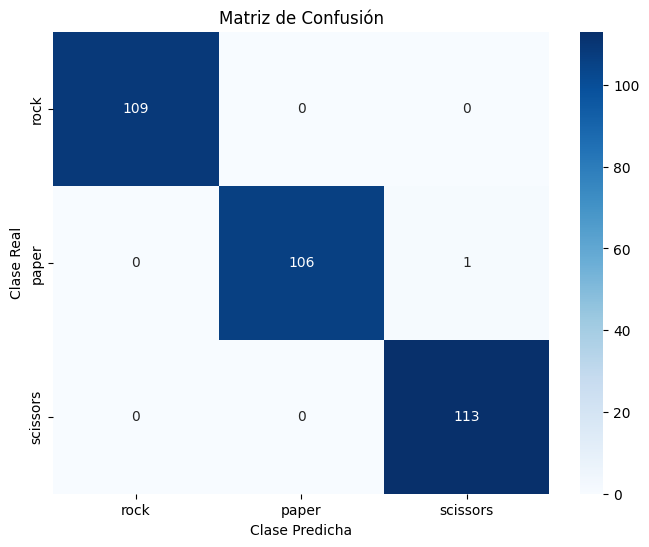

In [14]:
graficar_evaluacion_modelo(modelo_cnn, test_dataset, history_estrategia_1)

#### Interpretación de resultados
##### La evaluación de la Estrategia 1 (From Scratch) demuestra que, a pesar de implementar una arquitectura robusta con regularización exhaustiva (L2, Dropout y Data Augmentation), el modelo se enfrenta al límite inherente del tamaño de la muestra. Las curvas de aprendizaje revelan que la red debe invertir una gran cantidad de épocas y cómputo simplemente para descubrir extractores de características visuales básicas (bordes, contrastes y formas geométricas elementales) antes de poder comprender la semántica del dataset (Piedra, Papel o Tijera).

##### Para superar la barrera antes mencionada y el sesgo inductivo, planteamos la Estrategia 2. En la siguiente fase, abandonaremos el aprendizaje desde cero para aplicar técnicas de Transfer Learning. Utilizaremos una arquitectura pre-entrenada, aprovechando la jerarquía visual generalista que estas redes ya han extraído al procesar los millones de imágenes del dataset ImageNet. Nuestro objetivo será aislar la base convolucional mediante la congelación de pesos y aplicar un Fine-Tuning exclusivamente en la capa superior adaptada a nuestro dominio de tres clases, esperando una convergencia más rápida y una precisión superior en el conjunto de validación.

## Estrategia 2: Red pre-entrenada

### Primera Arquitectura Pre-entrenada: MobileNet

#### Carga del conjunto de datos
##### Para garantizar una comparación justa con la Estrategia 1, se emplea el mismo conjunto de datos Rock-Paper-Scissors, manteniendo la misma partición de entrenamiento, validación y test.

In [15]:
# Los splits ya se crearon en la primera estrategia.


#### Inspección del conjunto de datos
#####Se verifican las clases presentes y se visualizan ejemplos de imágenes para comprobar la correcta carga de los datos.

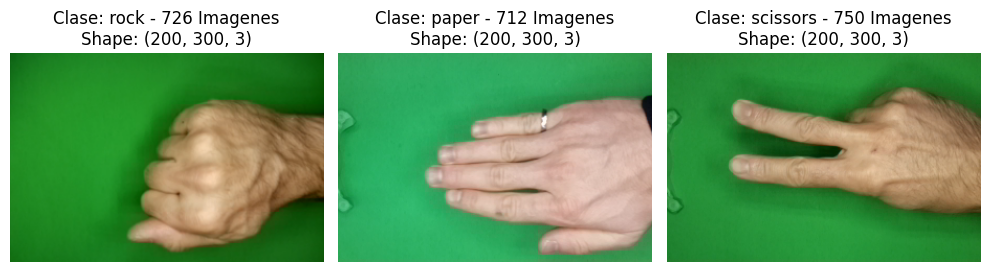

In [16]:
ver_dataset_original(ruta=RUTA_DATASET, clases=CLASES)

#### Acondicionamiento del conjunto de datos

Found 1531 files belonging to 3 classes.
Found 328 files belonging to 3 classes.
Found 329 files belonging to 3 classes.


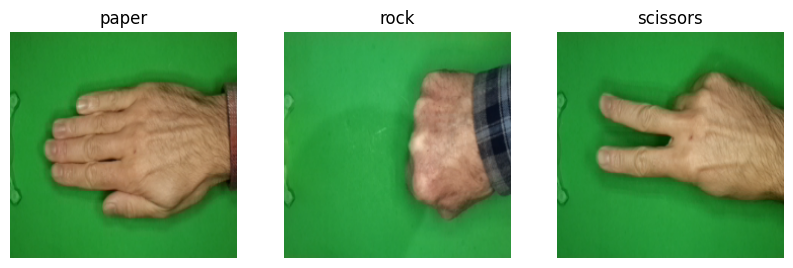

In [17]:
import tensorflow as tf

train_dataset_to_mobile_net, val_dataset_to_mobile_net, test_dataset_to_mobile_net = obtener_datasets(RUTA_SPLITS)
ver_dataset(train_dataset_to_mobile_net)
train_dataset_to_mobile_net, val_dataset_to_mobile_net, test_dataset_to_mobile_net = optimizar_rendimiento_dataset(train_dataset_to_mobile_net, val_dataset_to_mobile_net, test_dataset_to_mobile_net)


#### Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución
##### Se implementa Transfer Learning mediante MobileNetV2 preentrenada sobre ImageNet. La base convolucional se congela para conservar las características visuales aprendidas y se añaden capas densas para la clasificación específica de Piedra, Papel o Tijera.

In [18]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2

def construir_modelo_transfer_learning(input_shape=(224,224,3), num_classes=3):

    data_augmentation = Sequential(name="Data_Augmentation")
    data_augmentation = agregar_capas_aumento_datos(data_augmentation, input_shape)

    base_model_mobile_net = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )

    base_model_mobile_net.trainable = False

    model = Sequential([
        data_augmentation,
        base_model_mobile_net,
        GlobalAveragePooling2D(),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    return model

modelo_mobile_net_transfer_learning = construir_modelo_transfer_learning()
modelo_mobile_net_transfer_learning.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### Monitorización del proceso de entrenamiento para la toma de decisiones

In [19]:
from tensorflow.keras.optimizers import Adam

# Fase 1 de Entrenamiento (Entrenamos capa de salida)
modelo_mobile_net_transfer_learning.compile(
  optimizer=Adam(learning_rate=0.001),
  loss='categorical_crossentropy',
  metrics=['accuracy']
)

callbacks_mobilenet_fase_1 = obtener_callbacks_entrenamiento(nombre_modelo_checkpoint="modelo_from_mobile_fase1.keras",
                                                             patience_early_stopping=5)

history_fase_1_mobile_net = modelo_mobile_net_transfer_learning.fit(
    train_dataset_to_mobile_net,
    validation_data=val_dataset_to_mobile_net,
    epochs=15,
    callbacks=callbacks_mobilenet_fase_1,
    verbose=1
)

# Fase 2 de Entrenamiento (Se reentrena todas las capas incluidas las de MobileNet)
base_model_mobile_net = modelo_mobile_net_transfer_learning.layers[1]
base_model_mobile_net.trainable = True

fine_tune_at = 145
for layer in base_model_mobile_net.layers[:fine_tune_at]:
  layer.trainable = False

modelo_mobile_net_transfer_learning.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Calculamos la época inicial para que el gráfico de historial tenga sentido continuo
initial_epoch = history_fase_1_mobile_net.epoch[-1] + 1
FINE_TUNE_EPOCHS = 20
total_epochs = initial_epoch + FINE_TUNE_EPOCHS

callbacks_mobile_net_transfer_learning = obtener_callbacks_entrenamiento(nombre_modelo_checkpoint="estrategia_2_from_mobile_net.keras")

history_mobile_net_transfer_learning = modelo_mobile_net_transfer_learning.fit(
    train_dataset_to_mobile_net,
    validation_data=val_dataset_to_mobile_net,
    epochs=total_epochs,
    initial_epoch=initial_epoch,
    callbacks=callbacks_mobile_net_transfer_learning,
    verbose=1
)

print("\n¡Entrenamiento finalizado! El mejor modelo ha sido guardado.")

El mejor modelo se guardara en: ./modelos_guardados_rockpaperscissors/modelo_from_mobile_fase1.keras
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.5495 - loss: 1.0031
Epoch 1: val_loss improved from None to 0.29759, saving model to ./modelos_guardados_rockpaperscissors/modelo_from_mobile_fase1.keras

Epoch 1: finished saving model to ./modelos_guardados_rockpaperscissors/modelo_from_mobile_fase1.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 119ms/step - accuracy: 0.6930 - loss: 0.7057 - val_accuracy: 0.9085 - val_loss: 0.2976 - learning_rate: 0.0010
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8434 - loss: 0.4095
Epoch 2: val_loss improved from 0.29759 to 0.23892, saving model to ./modelos_guardados_rockpaperscissors/modelo_from_mobile_fase1.keras

Epoch 2: finished saving model to ./modelos_guardados_rockpaperscissors/modelo_from_mobile_fase1.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.8576 - loss: 0.3599 - val_accuracy: 0.9238 - val_loss:

#### Evaluación del modelo predictivo y planteamiento de la siguiente prueba experimental
##### Se evalúa el desempeño final del modelo.

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9696 - loss: 0.0976


### Evaluación Cuantitativa Global (Test)

,Métrica,Valor obtenido
0,Pérdida (Loss),0.0976
1,Precisión (Accuracy),96.96%


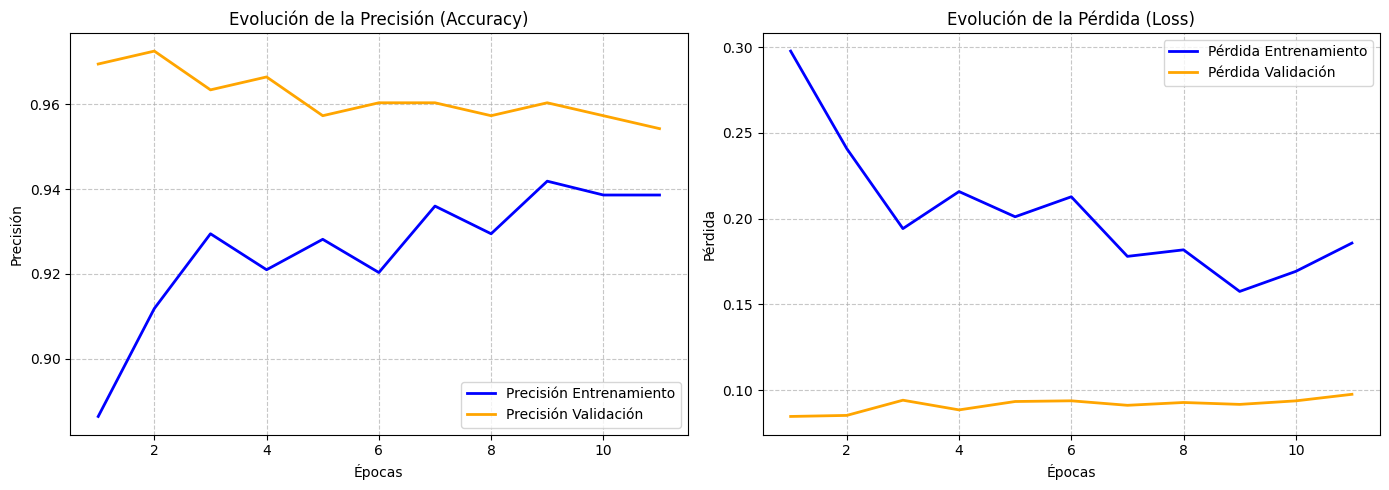

### Análisis de Errores y Rendimiento por Clase

,Precisión (Precision),Exhaustividad (Recall),F1-Score,Total de Imágenes (Support)
rock,0.9636,0.9725,0.9680,109
paper,0.9533,0.9533,0.9533,107
scissors,0.9911,0.9823,0.9867,113


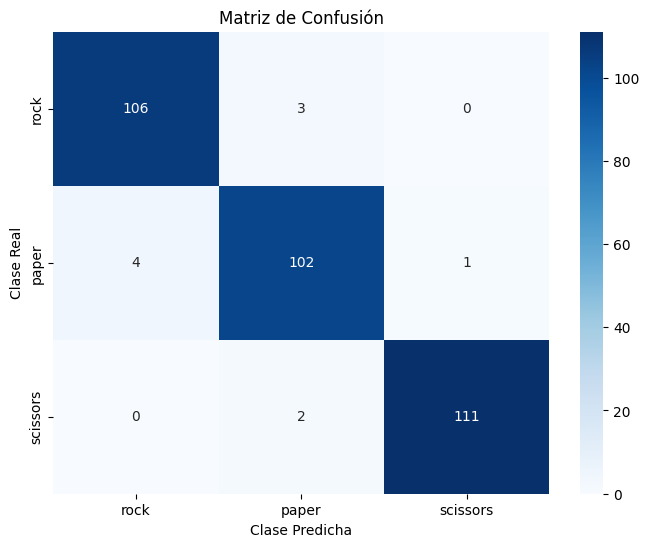

In [20]:
graficar_evaluacion_modelo(modelo_mobile_net_transfer_learning, test_dataset_to_mobile_net, history_mobile_net_transfer_learning)

#### Interpretación de resultados
##### Los resultados obtenidos muestran que la estrategia basada en Transfer Learning logra una convergencia más rápida que la CNN entrenada desde cero. Esto se debe a que MobileNetV2 aprovecha características visuales previamente aprendidas sobre ImageNet, reduciendo la cantidad de datos necesarios para alcanzar un buen desempeño. La comparación de métricas permitirá determinar si la estrategia propuesta supera a la arquitectura desarrollada desde cero en términos de precisión y capacidad de generalización.

##### El entrenamiento de MobileNetV2 presentó una dinámica de aprendizaje mucho más compleja. En el primer experimento de Fine-Tuning, donde se descongelaron las últimas 54 capas (a partir de la capa 100), el modelo sufrió un colapso en su rendimiento conocido como "Olvido Catastrófico" (Catastrophic Forgetting). Lo mismo ocurrio cuando en el segundo experimento de Fine-Tuning, donde se descongelaron las últimas 34 capas ocurrio lo mismo, aunque si hubo mejoria. Para mitigar este problema, fue necesario plantear un ajuste de hiperparámetros, restringiendo la sintonía fina a las últimas 10 capas (fine_tune_at = 145). Esta corrección logró estabilizar la actualización del gradiente, permitiendo que MobileNetV2 recuperara su capacidad de generalización.

### Segunda Arquitectura Pre-entrenada: VGG16

#### Carga del conjunto de datos

In [21]:
# Los splits ya se crearon en la primera estrategia.


#### Inspección del conjunto de datos

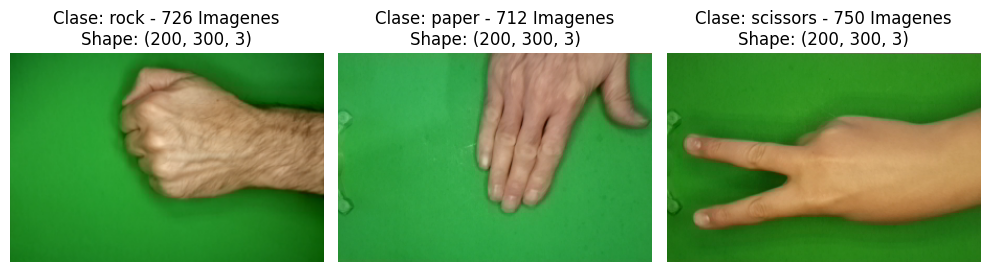

In [22]:
ver_dataset_original(ruta=RUTA_DATASET, clases=CLASES)

#### Acondicionamiento del conjunto de datos

Found 1531 files belonging to 3 classes.
Found 328 files belonging to 3 classes.
Found 329 files belonging to 3 classes.


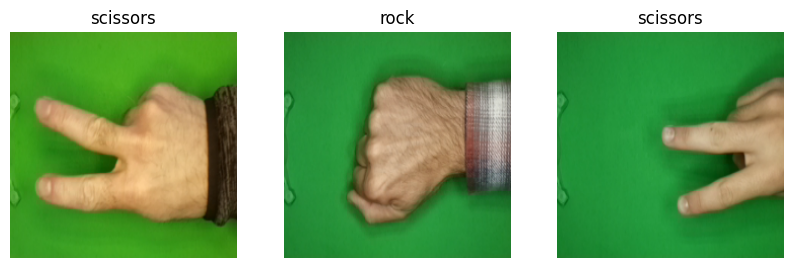

In [23]:
train_dataset_to_vgg, val_dataset_to_vgg, test_dataset_to_vgg = obtener_datasets(RUTA_SPLITS)
ver_dataset(train_dataset_to_vgg)
train_dataset_to_vgg, val_dataset_to_vgg, test_dataset_to_vgg = optimizar_rendimiento_dataset(train_dataset_to_vgg, val_dataset_to_vgg, test_dataset_to_vgg)


#### Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución

In [24]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

def construir_modelo_vgg16(input_shape=(224, 224, 3), num_classes=3):
    data_augmentation = Sequential(name="Data_Augmentation_VGG16")
    data_augmentation = agregar_capas_aumento_datos(data_augmentation, input_shape)

    base_model_vgg = VGG16(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )

    base_model_vgg.trainable = False

    model = Sequential([
        data_augmentation,
        base_model_vgg,
        GlobalAveragePooling2D(),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    return model

modelo_vgg = construir_modelo_vgg16()
modelo_vgg.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation_VGG16         │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

#### Monitorización del proceso de entrenamiento para la toma de decisiones

In [25]:
from tensorflow.keras.optimizers import Adam

# Fase 1 de Entrenamiento (Entrenamos capa de salida)
modelo_vgg.compile(
  optimizer=Adam(learning_rate=0.001),
  loss='categorical_crossentropy',
  metrics=['accuracy']
)

callbacks_vgg_16_fase_1 = obtener_callbacks_entrenamiento(nombre_modelo_checkpoint="modelo_vgg_16_fase1.keras",
                                                             patience_early_stopping=5)

history_fase_1_vgg_16 = modelo_vgg.fit(
    train_dataset_to_vgg,
    validation_data=val_dataset_to_vgg,
    epochs=15,
    callbacks=callbacks_vgg_16_fase_1
)

# Fase 2 de Entrenamiento (Se reentrena todas las capas incluidas las de MobileNet)
base_model_vgg = modelo_vgg.layers[1]
base_model_vgg.trainable = True

fine_tune_at = 15
for layer in base_model_vgg.layers[:fine_tune_at]:
  layer.trainable = False

modelo_vgg.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Calculamos la época inicial para que el gráfico de historial tenga sentido continuo
initial_epoch = history_fase_1_vgg_16.epoch[-1] + 1
FINE_TUNE_EPOCHS = 20
total_epochs = initial_epoch + FINE_TUNE_EPOCHS

callbacks_vgg_16_transfer_learning = obtener_callbacks_entrenamiento(nombre_modelo_checkpoint="estrategia_2_from_vgg_16.keras")

history_vgg_transfer_learning = modelo_vgg.fit(
    train_dataset_to_vgg,
    validation_data=val_dataset_to_vgg,
    epochs=total_epochs,
    initial_epoch=initial_epoch,
    callbacks=callbacks_vgg_16_transfer_learning,
    verbose=1
)

print("\n¡Entrenamiento finalizado! El mejor modelo ha sido guardado.")

El mejor modelo se guardara en: ./modelos_guardados_rockpaperscissors/modelo_vgg_16_fase1.keras
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.6585 - loss: 1.4341
Epoch 1: val_loss improved from None to 0.08360, saving model to ./modelos_guardados_rockpaperscissors/modelo_vgg_16_fase1.keras

Epoch 1: finished saving model to ./modelos_guardados_rockpaperscissors/modelo_vgg_16_fase1.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 228ms/step - accuracy: 0.8138 - loss: 0.6803 - val_accuracy: 0.9756 - val_loss: 0.0836 - learning_rate: 0.0010
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9421 - loss: 0.1893
Epoch 2: val_loss improved from 0.08360 to 0.05459, saving model to ./modelos_guardados_rockpaperscissors/modelo_vgg_16_fase1.keras

Epoch 2: finished saving model to ./modelos_guardados_rockpaperscissors/modelo_vgg_16_fase1.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 200ms/step - accuracy: 0.9451 - loss: 0.1674 - val_accuracy: 0.9817 - val_loss: 0.0546 - learning_ra

#### Evaluación del modelo predictivo y planteamiento de la siguiente prueba experimental

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.9939 - loss: 0.0168


### Evaluación Cuantitativa Global (Test)

,Métrica,Valor obtenido
0,Pérdida (Loss),0.0168
1,Precisión (Accuracy),99.39%


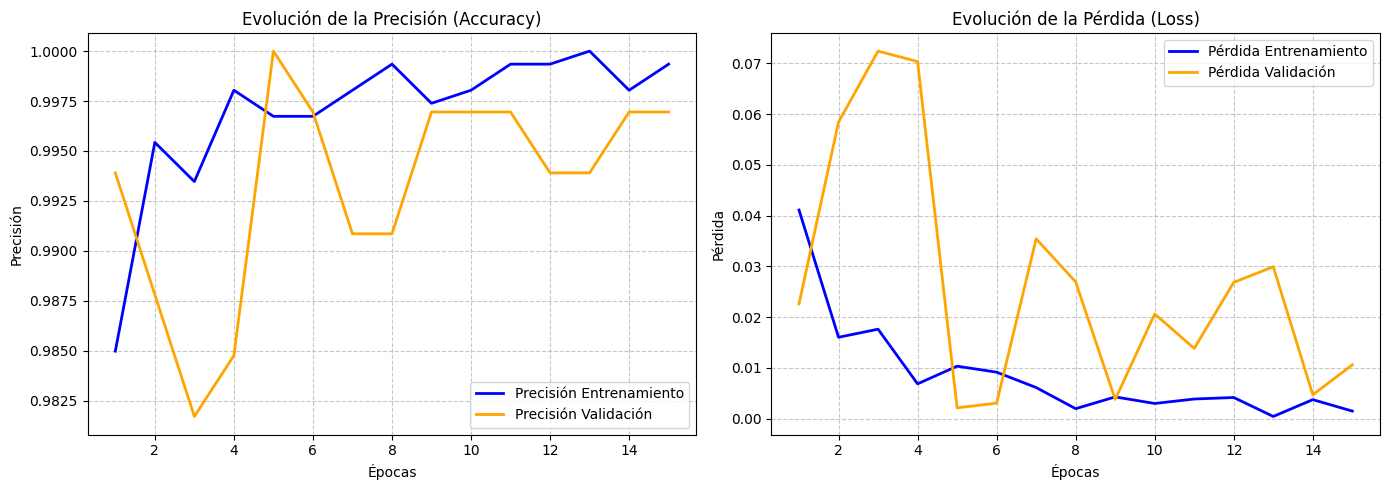

### Análisis de Errores y Rendimiento por Clase

,Precisión (Precision),Exhaustividad (Recall),F1-Score,Total de Imágenes (Support)
rock,1.0000,1.0000,1.0000,109
paper,0.9907,0.9907,0.9907,107
scissors,0.9912,0.9912,0.9912,113


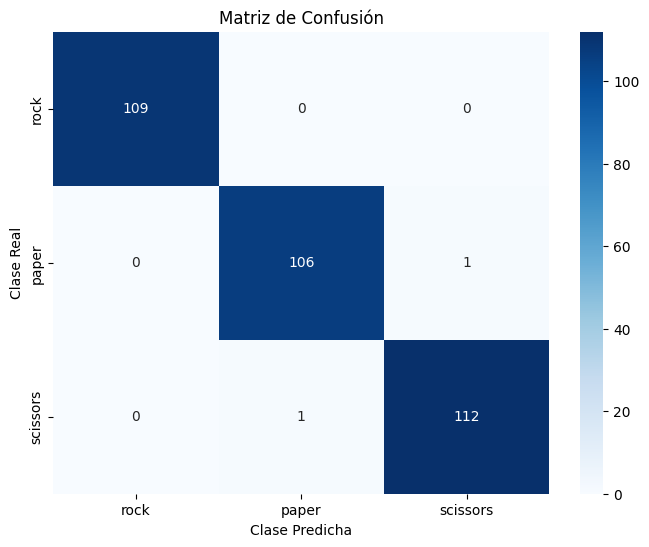

In [26]:
graficar_evaluacion_modelo(modelo_vgg, test_dataset_to_vgg, history_vgg_transfer_learning)

#### Interpretación de resultados

##### Durante la Fase 1 (Extracción de Características), VGG16 demostró una rápida adaptación de su nueva capa clasificadora gracias a la robustez de los mapas de características genéricos importados de ImageNet. Al transicionar a la Fase 2 (Fine-Tuning), el modelo evidenció una convergencia muy estable. Este comportamiento predecible se debe a dos factores arquitectónicos:

##### Congelamiento conservador: Al descongelar únicamente a partir de la capa 15 (el último bloque convolucional de sus 19 capas totales), se preservó intacta la base de extracción visual, evitando la sobreescritura de pesos. **Lección aprendida de los experimentos realizados con el modelo anterior (MobileNetV2)**.

##### Naturaleza de las convoluciones: VGG16 utiliza convoluciones estándar densas. Aunque estas operaciones hacen que el modelo sea computacionalmente muy pesado (millones de parámetros), garantizan un gradiente altamente estable y resistente frente al ruido de un dataset pequeño, protegiendo al modelo del sobreajuste abrupto.

## Conclusiones

Tras la evaluación experimental de las estrategias propuestas para la clasificación del conjunto de datos (Piedra, Papel, Tijera), los resultados empíricos arrojan conclusiones de alto valor analítico respecto al diseño y entrenamiento de Redes Neuronales Convolucionales (CNNs) en escenarios de datos limitados.

La comparativa entre el diseño desde cero y la transferencia de conocimiento revela las siguientes dinámicas fundamentales:

1. El Mérito y la Adaptabilidad del Diseño From Scratch
Sorprendentemente, la red neuronal diseñada desde cero (Estrategia 1) logró un rendimiento altamente competitivo. Al no tener que "desaprender" un dominio previo generalista (como ImageNet) y contar con un régimen de entrenamiento prolongado (límite de 100 épocas regulado por Early Stopping), el modelo adaptó sus filtros exclusivamente a las características morfológicas del dataset. El uso agresivo de Data Augmentation y Dropout fue fundamental para evitar la memorización, demostrando que una arquitectura modesta pero bien regularizada puede capturar eficientemente la varianza geométrica de un problema restringido.

2. La Fragilidad de MobileNetV2 puede verse como el coste de la Eficiencia, ya que, su comportamiento demostró ser el más complejo. Inicialmente, al descongelar una gran porción de la red, el modelo sufrió un severo olvido catastrófico (catastrophic forgetting), destruyendo sus pesos pre-entrenados y colapsando su precisión. Fue necesario un ajuste restrictivo extremo (descongelar solo las últimas 10 capas) para estabilizar su aprendizaje. Esto corrobora un principio crítico del Deep Learning: las convoluciones separables en profundidad (depthwise separable convolutions), si bien son brillantes para la eficiencia y la inferencia rápida, poseen gradientes muy sensibles. Son arquitecturas frágiles que requieren un control milimétrico al someterse a transferencia de aprendizaje con escasez de datos.

3. Se evidenció la robustez de VGG16 al consolidarse como el modelo más estable y predecible durante el Fine-Tuning. Al descongelar únicamente su último bloque convolucional (a partir de la capa 15), se protegió la jerarquía de extracción de características de bajo nivel. Además, se evidenció empíricamente que sus convoluciones densas y estándar, aunque costosas a nivel computacional (decenas de millones de parámetros), proporcionan un paisaje de pérdida (loss landscape) sumamente estable. Esta "fuerza bruta" arquitectónica le otorga una alta tolerancia frente al ruido y previene el sobreajuste abrupto al reentrenarse con pocos datos.

_*Conclusión Final*_

Para la resolución de tareas de clasificación visual en dominios con limitación severa de muestras, el éxito predictivo depende más de la restricción paramétrica del gradiente que de la modernidad inherente de la red. Mientras que enfoques ligeros como MobileNetV2 requieren un ajuste de hiperparámetros hiper-conservador para no colapsar, arquitecturas clásicas como VGG16 o diseños focalizados From Scratch ofrecen una tolerancia y una estabilidad muy superior. En este escenario empírico, la robustez paramétrica superó a la eficiencia computacional.